# 06 - Métricas

Avaliação dos três modelos no conjunto de teste (20 imagens, 5 por classe).

| Modelo | Depois do extrator (igual nos três) | Parâmetros |
|---|---|---|
| CNN | `Flatten` + `Dense(128)` + `Dropout` + `Dense(4)` | 12.938.948 |
| FCNN | `Conv 1x1 (128)` + `Dropout` + `Conv 1x1 (4)` + `GlobalAveragePooling2D` | 110.276 |
| Encoder-Decoder | 3 `Conv2DTranspose` + a cabeça da FCNN | 337.828 |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (confusion_matrix, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve,
                             accuracy_score, precision_score, recall_score, f1_score,
                             precision_recall_fscore_support)
from sklearn.preprocessing import label_binarize

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

## Dados de teste e previsões

In [2]:
splits = pd.read_csv(PROJECT_ROOT / 'data' / 'annotations' / 'splits.csv')
classes = sorted(splits['classe'].unique())
teste = splits[splits['conjunto'] == 'teste'].reset_index(drop=True)

X_test, y_true = [], []
for _, row in teste.iterrows():
    caminho = PROJECT_ROOT / row['caminho'].replace('spectrograms', 'mod_spectograms')
    img = Image.open(caminho).convert('RGB').resize((224, 224))
    X_test.append(np.array(img) / 255.0)
    y_true.append(classes.index(row['classe']))
X_test = np.array(X_test, dtype='float32')
y_true = np.array(y_true)
y_true_bin = label_binarize(y_true, classes=[0, 1, 2, 3])

print(classes, X_test.shape)

modelos = {'CNN': 'modelo_cnn.keras', 'FCNN': 'modelo_fcnn.keras', 'Encoder-Decoder': 'modelo_encdec.keras'}
prob = {nome: tf.keras.models.load_model(PROJECT_ROOT / 'models' / arquivo).predict(X_test, verbose=0)
        for nome, arquivo in modelos.items()}
pred = {nome: p.argmax(axis=1) for nome, p in prob.items()}

['ICTAL', 'NORMAL', 'POS_ICTAL', 'PRE_ICTAL'] (20, 224, 224, 3)


## Métricas gerais

Precisão, recall e F1 são a média das 4 classes (macro). A linha tracejada é o acaso (25%).

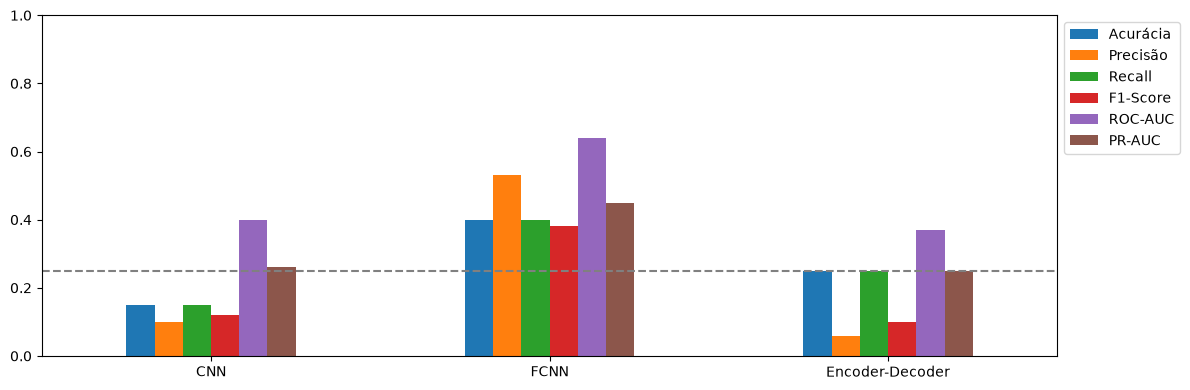

,Acurácia,Precisão,Recall,F1-Score,ROC-AUC,PR-AUC
CNN,0.15,0.10,0.15,0.12,0.40,0.26
FCNN,0.40,0.53,0.40,0.38,0.64,0.45
Encoder-Decoder,0.25,0.06,0.25,0.10,0.37,0.25


In [3]:
comparacao = pd.DataFrame({
    nome: {
        'Acurácia': accuracy_score(y_true, pred[nome]),
        'Precisão': precision_score(y_true, pred[nome], average='macro', zero_division=0),
        'Recall': recall_score(y_true, pred[nome], average='macro', zero_division=0),
        'F1-Score': f1_score(y_true, pred[nome], average='macro', zero_division=0),
        'ROC-AUC': roc_auc_score(y_true_bin, prob[nome], multi_class='ovr'),
        'PR-AUC': average_precision_score(y_true_bin, prob[nome]),
    } for nome in modelos
}).T.round(2)

comparacao.plot(kind='bar', figsize=(12, 4), rot=0)
plt.ylim(0, 1)
plt.axhline(0.25, color='gray', linestyle='--')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()
comparacao

## Métricas por classe

In [4]:
por_classe = {}
for nome in modelos:
    precisao, recall, f1, _ = precision_recall_fscore_support(y_true, pred[nome], labels=range(4), zero_division=0)
    por_classe[nome] = pd.DataFrame({
        'Precisão': precisao, 'Recall': recall, 'F1': f1,
        'ROC-AUC': roc_auc_score(y_true_bin, prob[nome], average=None),
    }, index=classes)
pd.concat(por_classe, axis=1).round(2)

CNN                          FCNN                       \
          Precisão Recall    F1 ROC-AUC Precisão Recall    F1 ROC-AUC   
ICTAL         0.12    0.2  0.15    0.28     1.00    0.2  0.33    0.76   
NORMAL        0.29    0.4  0.33    0.48     0.25    0.2  0.22    0.61   
POS_ICTAL     0.00    0.0  0.00    0.43     0.36    0.8  0.50    0.59   
PRE_ICTAL     0.00    0.0  0.00    0.43     0.50    0.4  0.44    0.61   

          Encoder-Decoder                      
                 Precisão Recall   F1 ROC-AUC  
ICTAL                0.00    0.0  0.0    0.44  
NORMAL               0.25    1.0  0.4    0.43  
POS_ICTAL            0.00    0.0  0.0    0.28  
PRE_ICTAL            0.00    0.0  0.0    0.32

## Matrizes de confusão

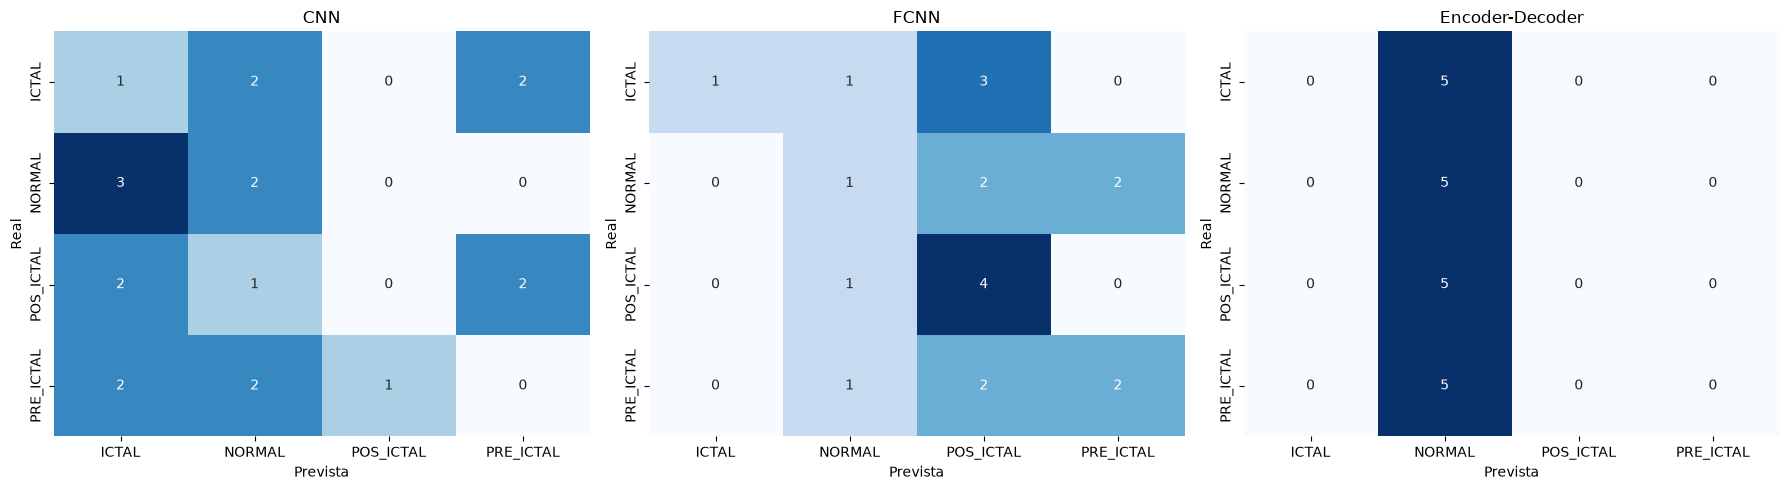

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, nome in zip(axes, modelos):
    sns.heatmap(confusion_matrix(y_true, pred[nome]), annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_title(nome)
    ax.set_xlabel('Prevista')
    ax.set_ylabel('Real')
plt.tight_layout()
plt.show()

## Curvas ROC e Precision-Recall

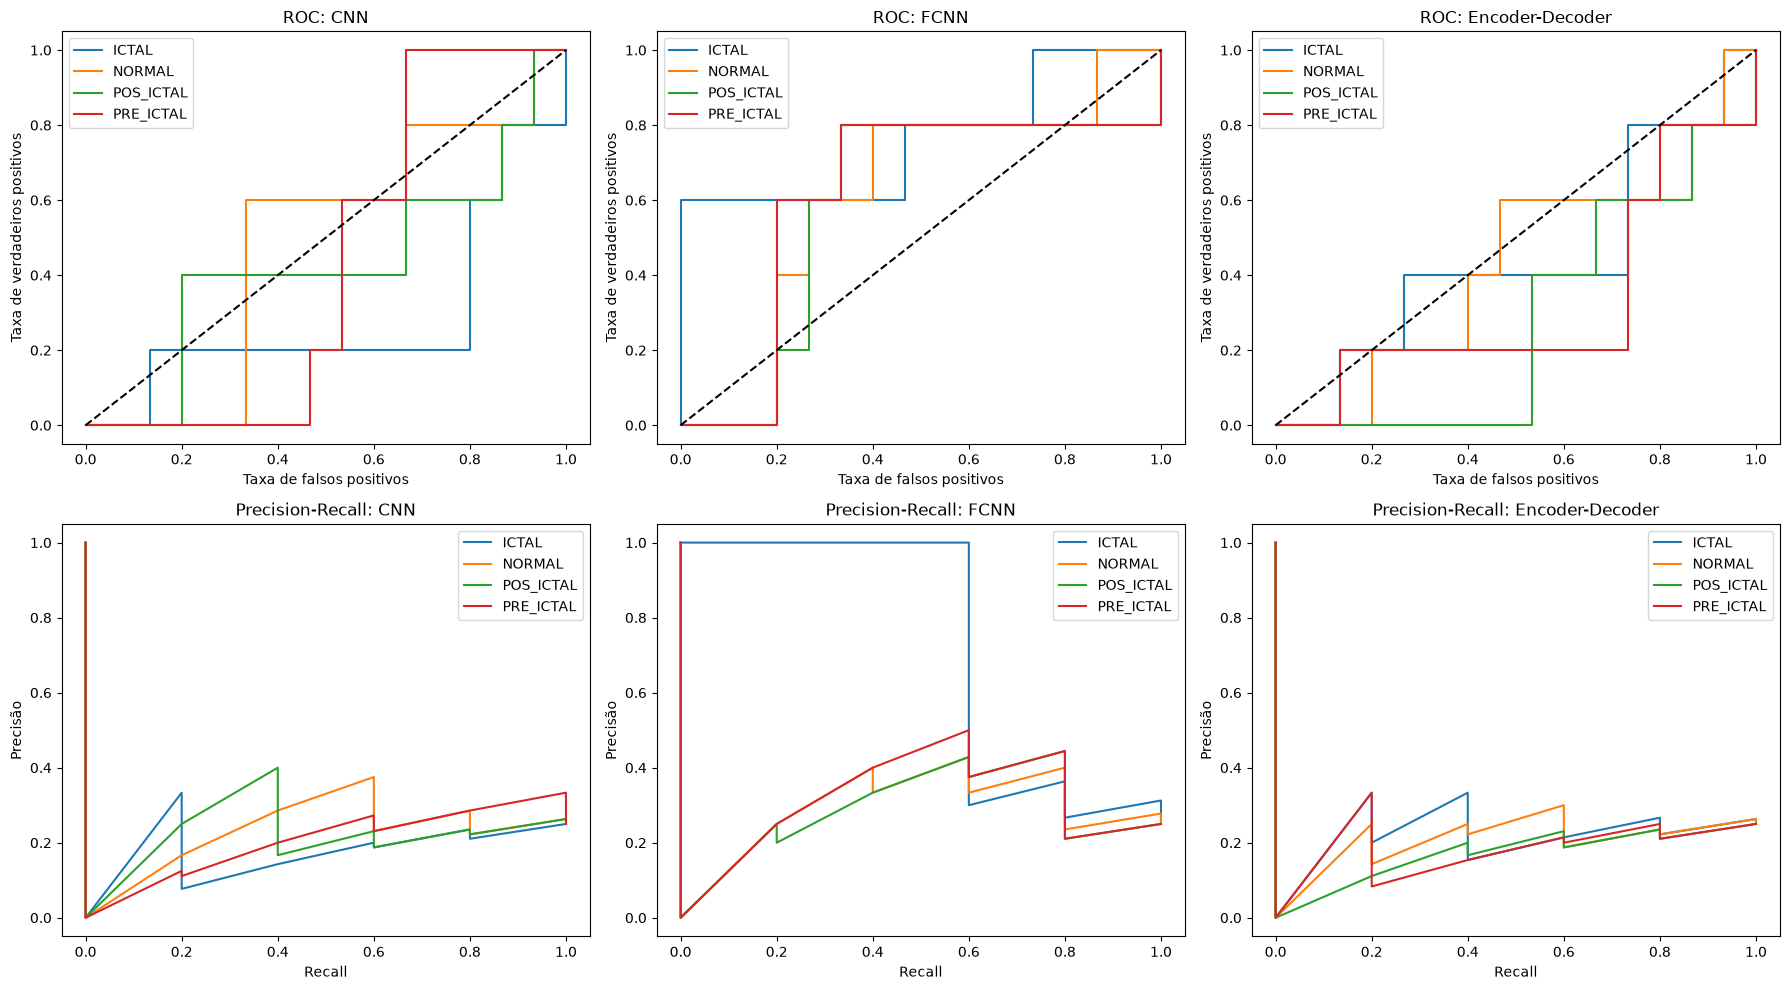

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for j, nome in enumerate(modelos):
    for i, classe in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], prob[nome][:, i])
        axes[0, j].plot(fpr, tpr, label=classe)
        precisao, recall, _ = precision_recall_curve(y_true_bin[:, i], prob[nome][:, i])
        axes[1, j].plot(recall, precisao, label=classe)
    axes[0, j].plot([0, 1], [0, 1], 'k--')
    axes[0, j].set(title=f'ROC: {nome}', xlabel='Taxa de falsos positivos', ylabel='Taxa de verdadeiros positivos')
    axes[1, j].set(title=f'Precision-Recall: {nome}', xlabel='Recall', ylabel='Precisão')
    axes[0, j].legend()
    axes[1, j].legend()
plt.tight_layout()
plt.show()

## Análise dos erros

Previsão de cada modelo por imagem, falsos positivos (FP) e falsos negativos (FN) por classe, e casos ambíguos (diferença < 0,15 entre as duas maiores probabilidades).

In [7]:
por_imagem = pd.DataFrame({
    'arquivo': teste['caminho'].str.split('/').str[-1],
    'real': [classes[i] for i in y_true],
})
for nome in modelos:
    por_imagem[nome] = [classes[i] for i in pred[nome]]
display(por_imagem)

fp_fn = pd.concat({
    nome: pd.DataFrame({
        'FP': [((pred[nome] == i) & (y_true != i)).sum() for i in range(4)],
        'FN': [((y_true == i) & (pred[nome] != i)).sum() for i in range(4)],
    }, index=classes) for nome in modelos
}, axis=1)
display(fp_fn)

ordenada = {nome: np.sort(p, axis=1) for nome, p in prob.items()}
pd.DataFrame({
    'Erros': [(pred[nome] != y_true).sum() for nome in modelos],
    'Casos ambíguos': [((o[:, -1] - o[:, -2]) < 0.15).sum() for o in ordenada.values()],
}, index=list(modelos))

,arquivo,real,CNN,FCNN,Encoder-Decoder
0,PN13-1_seizure01_ictal.png,ICTAL,ICTAL,POS_ICTAL,NORMAL
1,PN13-1_seizure01_pre_ictal.png,PRE_ICTAL,POS_ICTAL,POS_ICTAL,NORMAL
2,PN13-1_seizure01_pos_ictal.png,POS_ICTAL,ICTAL,POS_ICTAL,NORMAL
3,PN13-1_seizure01_normal.png,NORMAL,ICTAL,POS_ICTAL,NORMAL
4,PN13-2_seizure02_ictal.png,ICTAL,PRE_ICTAL,NORMAL,NORMAL
5,PN13-2_seizure02_pre_ictal.png,PRE_ICTAL,ICTAL,NORMAL,NORMAL
6,PN13-2_seizure02_pos_ictal.png,POS_ICTAL,ICTAL,NORMAL,NORMAL
7,PN13-2_seizure02_normal.png,NORMAL,NORMAL,NORMAL,NORMAL
8,PN13-3_seizure03_ictal.png,ICTAL,NORMAL,ICTAL,NORMAL
9,PN13-3_seizure03_pre_ictal.png,PRE_ICTAL,ICTAL,POS_ICTAL,NORMAL


CNN    FCNN    Encoder-Decoder   
           FP FN   FP FN              FP FN
ICTAL       7  4    0  4               0  5
NORMAL      5  3    3  4              15  0
POS_ICTAL   1  5    7  1               0  5
PRE_ICTAL   4  5    2  3               0  5

,Erros,Casos ambíguos
CNN,17,1
FCNN,12,10
Encoder-Decoder,15,20


## Respostas

| Pergunta | CNN | FCNN | Encoder-Decoder |
|---|---|---|---|
| Classe com melhor desempenho | NORMAL (F1 0,33) | POS_ICTAL (F1 0,50) | NORMAL (F1 0,40), só porque previu NORMAL para tudo |
| Classe mais difícil | POS_ICTAL e PRE_ICTAL (F1 0) | NORMAL (F1 0,22) | ICTAL, POS_ICTAL e PRE_ICTAL (F1 0) |
| Acertos | 3 de 20 (NORMAL 2, ICTAL 1) | 8 de 20 (POS_ICTAL 4, PRE_ICTAL 2, ICTAL 1, NORMAL 1) | 5 de 20 (todos NORMAL) |
| Mais confundidas | quase tudo vira ICTAL (7 FP) ou NORMAL (5 FP) | quase tudo vira POS_ICTAL (7 FP) | tudo vira NORMAL (15 FP) |
| Separação (ROC-AUC) | 0,40, pior que o acaso (0,50) | 0,64, a melhor (ICTAL 0,76) | 0,37, pior que o acaso |
| Curvas consistentes? | Não | Em parte, só ICTAL se destaca | Não |
| Casos ambíguos | 1, erra com confiança | 10 | 20, saída quase uniforme |

## Conclusão

- **Melhor modelo: FCNN** (acurácia 0,40, F1 0,38, ROC-AUC 0,64). Mesmo assim, são 8 acertos contra 5 esperados por acaso.
- **CNN:** decorou o treino (97% de acurácia no treino) e ficou abaixo do acaso no teste (15%).
- **Encoder-Decoder:** não aprendeu e previu NORMAL para as 20 imagens.
- **Limitações:** só 100 imagens de treino e 20 de teste, e os pacientes do teste (PN13, PN17) não aparecem no treino.
- **Próximos passos:** data augmentation, `EarlyStopping`, mais épocas para FCNN e Encoder-Decoder, e transfer learning.